# Explore > COLUMN 

> Have you donated money

# Imports

In [1]:
import matplotlib.pyplot as plt
from scipy import stats

from Q1.consts import *

from utils.read_csv_to_df import read_csv_to_df
from utils.plot_hist_with_normal_dist_overlay import plot_hist_with_normal_dist_overlay
from utils.rule_of_thumb__skewness import rule_of_thumb__skewness
from utils.rule_of_thumb__kurtosis import rule_of_thumb__kurtosis
from utils.plot_correlation_to_target import plot_correlation_to_target
from utils.preprocessing.transform import *

# Defaults

In [2]:
COLUMN = columns['G']

# Fetch Data

In [3]:
train_df = read_csv_to_df(path=TRAIN_PATH)

# Summary

In [4]:
train_df[COLUMN].info()

Generosity_stats = train_df[[COLUMN]].describe().T

q1, q3 = train_df[COLUMN].quantile(0.25), train_df[COLUMN].quantile(0.75)
iqr = q3 - q1
Generosity_stats['IQR outliers'] = (
	(train_df[COLUMN] < q1 - 1.5 * iqr) | (train_df[COLUMN] > q3 + 1.5 * iqr)
).sum()

<class 'pandas.core.series.Series'>
RangeIndex: 1559 entries, 0 to 1558
Series name: Generosity
Non-Null Count  Dtype  
--------------  -----  
1488 non-null   float64
dtypes: float64(1)
memory usage: 12.3 KB


In [5]:
missing_values_Generosity = train_df[COLUMN].isna().sum()
count_Generosity = train_df[COLUMN].count()

print(f"{missing_values_Generosity} missing values out of {count_Generosity} -> {round(missing_values_Generosity / count_Generosity, 2)}%")

71 missing values out of 1488 -> 0.05%


# Plots

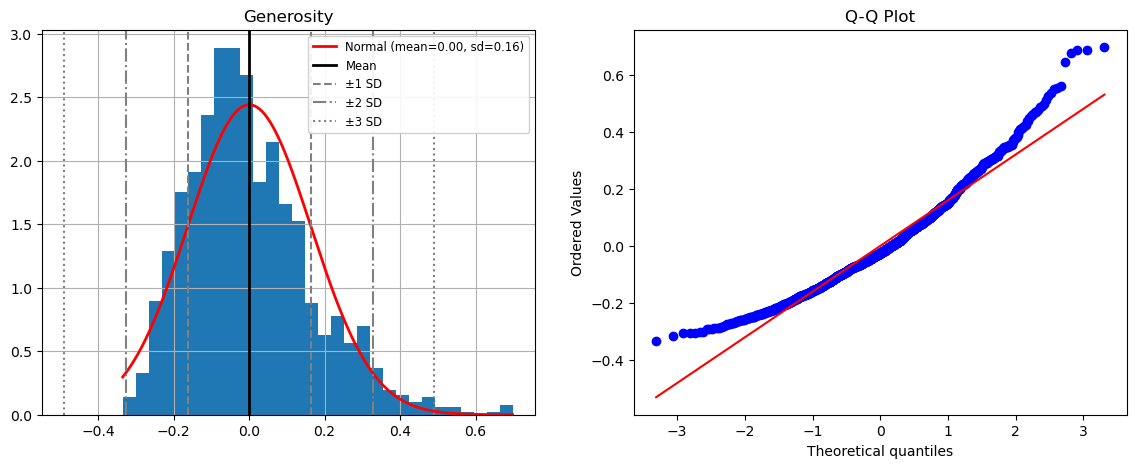

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_hist_with_normal_dist_overlay(
    series=train_df[COLUMN],
    bins=HIST_BINS,
    ax=ax1
)

stats.probplot(
	train_df[COLUMN].dropna(),
	dist="norm",
	plot=ax2)
ax2.set_title("Q-Q Plot")

plt.show()

# Correlation to Target

<Axes: title={'center': 'Life Ladder vs Generosity'}, xlabel='Generosity', ylabel='Life Ladder'>

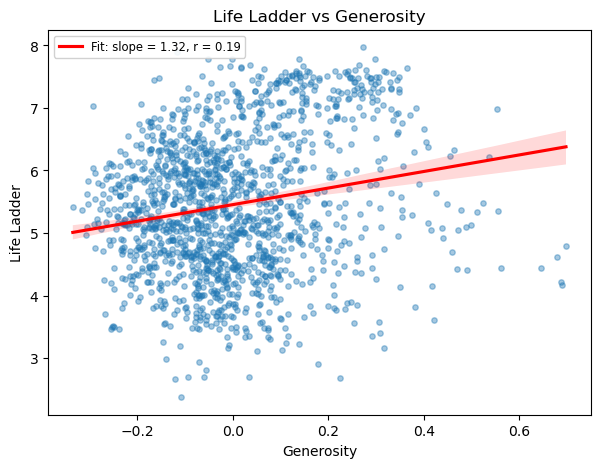

In [7]:
plot_correlation_to_target(
	df=train_df,
	feature="Generosity",
	target=TARGET,
)

In [8]:
correlation_to_target_Generosity = train_df[TARGET].corr(train_df["Generosity"])
print(f"Correlation: {correlation_to_target_Generosity:.3f}")

Correlation: 0.195


# Skew & Kurtosis

In [9]:
GenerositySkew = train_df[COLUMN].skew()
GenerositySkew_RuleOfThumb = rule_of_thumb__skewness(series=train_df["Generosity"])
GenerosityKurtosis = train_df[COLUMN].kurt()
GenerosityKurtosis_RuleOfThumb = rule_of_thumb__kurtosis(series=train_df[COLUMN])

print(f'Generosity Skew: {GenerositySkew:.3f} -> {GenerositySkew_RuleOfThumb}')
print(f'Generosity Kurtosis: {GenerosityKurtosis:.3f} -> {GenerosityKurtosis_RuleOfThumb}')

Generosity Skew: 0.828 -> Moderately skewed
Generosity Kurtosis: 0.945 -> Mesokurtic (near-normal tails)


In [10]:
GenerositySkewTransformed = compare_all_transforms(series=train_df["Generosity"])
GenerositySkewTransformed

,skew_before,skew_after,skew_diff,kurt_before,kurt_after,kurt_diff,skew_rule_after
transform,,,,,,,
quantile,0.828245,0.001744,-8.265016e-01,0.944684,0.656401,-0.288283,Roughly symmetric
rank,0.828245,-0.003261,-8.315063e-01,0.944684,-1.199335,-2.144019,Roughly symmetric
yeo_johnson,0.828245,0.025929,-8.023158e-01,0.944684,-0.315034,-1.259717,Roughly symmetric
clip,0.828245,0.681715,-1.465307e-01,0.944684,0.208546,-0.736138,Moderately skewed
shift,0.828245,0.828245,6.661338e-16,0.944684,0.944684,0.000000,Moderately skewed
reflect_log,0.828245,-1.227598,-2.055843e+00,0.944684,2.467293,1.522609,Highly skewed
square,0.828245,4.780408,3.952163e+00,0.944684,33.739058,32.794374,Highly skewed
cube,0.828245,8.151558,7.323313e+00,0.944684,87.872540,86.927856,Highly skewed
log,0.828245,NaN,NaN,0.944684,NaN,NaN,not allowed for this data


---

### Notes / Observations
#### General
- 71 missing values (4.6% of rows).
- Centered at 0 (mean 0.000, median -0.025, range -0.34 to 0.70), so it is a relative score rather than a raw share. Negative means less generous than expected for the country's income.
- Right skewed (skew 0.83), with a long tail of very generous countries: 31 high IQR outliers (above about 0.40) and none on the low side.
- Weakest link to happiness (r = 0.19). The scatter is mostly a shapeless cloud, and the confidence band widens on the right where data is sparse.
- Almost unrelated to GDP (r = -0.01), so the little it does add is new information. Closest links are Positive affect (r = 0.38) and Freedom (r = 0.33).
- **Takeaway:** weak predictor on its own; a candidate to drop or to let regularization decide.

#### Transforming
- Contains negative values, so log, log1p and sqrt are not allowed.
- square and cube make it far worse (skew 4.78, 8.15) because squaring folds the negatives onto the positives.
- yeo_johnson is the only magnitude keeping option that works: skew 0.83 to 0.03, kurtosis 0.94 to -0.32.
- **Pick:** yeo_johnson, fit on the train data only.

#### Scaling
- Already centered at 0, but its std (0.16) still differs from the other features, so StandardScaler keeps it consistent.
- The high outliers stretch the max, so MinMaxScaler would squeeze most countries into a narrow band.

#### Imputing
- All 26 rows missing GDP are also missing Generosity. Generosity is measured relative to income, so it cannot be computed without GDP.
- Weak links to every other feature (best is Positive affect, r = 0.38), so IterativeImputer or KNNImputer have little to work with.
- Median SimpleImputer (-0.025) is the practical choice, and better than the mean (0.000) given the right skew.